In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install segmentation_models_pytorch h5py tqdm

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.6 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, glob, re, random, time, json, shutil
import numpy as np, pandas as pd, h5py, torch
import torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED_SPLIT = 42                      # fixed split, never changes
OUT = '/content/drive/MyDrive/TerraSeg/phase3'
os.makedirs(f'{OUT}/runs', exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device, "| outputs ->", OUT)
if device.type == 'cpu':
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU")

Device: cuda | outputs -> /content/drive/MyDrive/TerraSeg/phase3


In [ ]:
#import dataset and load images/mask files

from huggingface_hub import snapshot_download
snapshot_download(repo_id="ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                  allow_patterns=["*train*"], local_dir="/content/l4s", max_workers=8)

def num(p): return int(re.findall(r'(\d+)\.h5$', p)[0])
img_files  = sorted(glob.glob('/content/l4s/images/train/image_*.h5'), key=num)
mask_files = sorted(glob.glob('/content/l4s/annotations/train/mask_*.h5'), key=num)
print(len(img_files), "images |", len(mask_files), "masks")
assert len(img_files) == len(mask_files) > 0
assert all(num(a) == num(b) for a, b in zip(img_files, mask_files)), "image/mask mismatch"

def first(h): return h[list(h.keys())[0]][:]
N = len(img_files)
X = np.zeros((N, 14, 128, 128), dtype=np.float32)
Y = np.zeros((N, 1, 128, 128), dtype=np.float32)
for i, (a, b) in enumerate(tqdm(list(zip(img_files, mask_files)))):
    with h5py.File(a) as h: X[i] = np.nan_to_num(first(h)).transpose(2, 0, 1)
    with h5py.File(b) as h: Y[i, 0] = first(h)

valid = np.array([np.abs(X[i, :12]).max() > 0 for i in range(N)])
valid_idx = np.where(valid)[0]
print(f"patches {N} | empty (all-zero) patches excluded: {(~valid).sum()} | usable: {len(valid_idx)}")
print(f"landslide pixel share (usable patches): {Y[valid_idx].mean()*100:.2f}%")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7603 files:   0%|          | 0/7603 [00:00<?, ?it/s]

3799 images | 3799 masks


  0%|          | 0/3799 [00:00<?, ?it/s]

patches 3799 | empty (all-zero) patches excluded: 0 | usable: 3799
landslide pixel share (usable patches): 2.32%


In [ ]:
#split dataset into training,validation,and testing sets

rng = np.random.RandomState(SEED_SPLIT)
perm = rng.permutation(valid_idx)
n = len(perm); n_tr, n_va = int(0.70 * n), int(0.15 * n)
train_idx, val_idx, test_idx = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
np.savez(f'{OUT}/split.npz', train=train_idx, val=val_idx, test=test_idx)
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}")

s1 = np.zeros(14, np.float64); s2 = np.zeros(14, np.float64); cnt = 0
for s in range(0, len(train_idx), 256):
    b = X[np.sort(train_idx[s:s + 256])].astype(np.float64)
    s1 += b.sum(axis=(0, 2, 3)); s2 += (b ** 2).sum(axis=(0, 2, 3)); cnt += b.shape[0] * 128 * 128
MEAN = (s1 / cnt).astype(np.float32)
STD = (np.sqrt(np.maximum(s2 / cnt - (s1 / cnt) ** 2, 1e-12)) + 1e-6).astype(np.float32)
json.dump({'mean': MEAN.tolist(), 'std': STD.tolist()}, open(f'{OUT}/norm_stats.json', 'w'))

m4, s4 = MEAN.reshape(1, 14, 1, 1), STD.reshape(1, 14, 1, 1)
for s in range(0, N, 256):
    X[s:s + 256] = (X[s:s + 256] - m4) / s4
print("normalised. channel 13 (DEM) raw mean/std:", round(float(MEAN[13]), 1), round(float(STD[13]), 1))
print(f"landslide share in TRAIN {Y[train_idx].mean()*100:.2f}% | VAL {Y[val_idx].mean()*100:.2f}% | TEST {Y[test_idx].mean()*100:.2f}%")

train 2659 | val 569 | test 571
normalised. channel 13 (DEM) raw mean/std: 1.6 1.1
landslide share in TRAIN 2.31% | VAL 2.45% | TEST 2.21%


In [ ]:
#Create the dataset loader and prepare the 14-channel input

ALL = list(range(14))

class PatchDS(Dataset):
    def __init__(self, idx, aug='none'):
        self.idx, self.aug = np.asarray(idx), aug
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = torch.from_numpy(X[j].copy())
        y = torch.from_numpy(Y[j].copy())
        if self.aug in ('flip', 'flip_rot'):
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        if self.aug == 'flip_rot':
            k = random.randint(0, 3)
            if k: x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (1, 2))
        return x, y

def loader(idx, aug='none', shuffle=False, bs=16, seed=0):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(PatchDS(idx, aug), batch_size=bs, shuffle=shuffle, generator=g if shuffle else None,
                      num_workers=2, pin_memory=True)

print("Dataset ready")

Dataset ready


In [ ]:
def dice_term(logits, t):
    p, tf = torch.sigmoid(logits).view(-1), t.view(-1)
    return 1 - (2 * (p * tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)

class BCEDiceLoss(nn.Module):
    def forward(self, logits, t):
        return F.binary_cross_entropy_with_logits(logits, t) + dice_term(logits, t)

class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, t):
        bce = F.binary_cross_entropy_with_logits(logits, t, reduction='none')
        p = torch.sigmoid(logits)
        pt = p * t + (1 - p) * (1 - t)                       # probability given to the correct class
        a = self.alpha * t + (1 - self.alpha) * (1 - t)
        focal = (a * (1 - pt) ** self.gamma * bce).sum() / t.sum().clamp(min=1.0)
        return focal + dice_term(logits, t)

LOSSES = {'bce_dice': BCEDiceLoss, 'focal_dice': FocalDiceLoss}

def build(attn=None, pretrained=True):
    return smp.Unet('resnet34', encoder_weights='imagenet' if pretrained else None,
                    in_channels=14, classes=1, decoder_attention_type=attn).to(device)

print("Losses and model builder ready")

Losses and model builder ready


In [ ]:
def metrics_from_counts(tp, fp, fn, tn):
    e = 1e-9
    prec, rec = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * prec * rec / (prec + rec + e),
            'Precision': prec, 'Recall': rec, 'PixelAcc': (tp + tn) / (tp + tn + fp + fn + e)}

@torch.no_grad()
def predict_probs(model, x, tta=False):
    model.eval()
    p = torch.sigmoid(model(x))
    if not tta:
        return p
    p = p + torch.sigmoid(model(x.flip(-1))).flip(-1)
    p = p + torch.sigmoid(model(x.flip(-2))).flip(-2)
    p = p + torch.sigmoid(model(x.flip([-1, -2]))).flip([-1, -2])
    return p / 4

@torch.no_grad()
def collect_probs(model, ldr, tta=False):
    P, T = [], []
    for x, y in ldr:
        P.append(predict_probs(model, x.to(device), tta)[:, 0].cpu().numpy().astype(np.float16))
        T.append(y[:, 0].numpy().astype(np.uint8))
    return np.concatenate(P), np.concatenate(T)

def metrics_from_probs(P, T, thr=0.5):
    p, t = P.astype(np.float32) > thr, T == 1
    return metrics_from_counts(float((p & t).sum()), float((p & ~t).sum()), float((~p & t).sum()), float((~p & ~t).sum()))

def evaluate(model, ldr, thr=0.5, tta=False):
    P, T = collect_probs(model, ldr, tta)
    return metrics_from_probs(P, T, thr)

print("Metrics ready")

Metrics ready


In [ ]:
#scSE attention

#scSE stands for Spatial and Channel Squeeze-and-Excitation.
#It helps the model focus on useful information.

#Channel attention helps identify which feature channels are important.
#Spatial attention helps identify which spatial regions are important.

EXPERIMENTS = {
    'E0_baseline': dict(loss='bce_dice',   attn=None,   aug='flip'),
    'E1_focal':    dict(loss='focal_dice', attn=None,   aug='flip'),
    'E2_scse':     dict(loss='bce_dice',   attn='scse', aug='flip'),
    'E3_rotaug':   dict(loss='bce_dice',   attn=None,   aug='flip_rot'),
    'E4_combined': dict(loss='focal_dice', attn='scse', aug='flip_rot'),
}
EPOCHS, PATIENCE, LR, FORCE = 40, 10, 5e-4, False

def rpath(name, seed): return f'{OUT}/runs/{name}_s{seed}.json'
def cpath(name, seed): return f'{OUT}/runs/{name}_s{seed}.pth'

def run_experiment(name, seed):
    if os.path.exists(rpath(name, seed)) and not FORCE:
        print(f"skip {name} seed {seed} (done)")
        return json.load(open(rpath(name, seed)))
    cfg = EXPERIMENTS[name]
    print("\n" + "=" * 72 + f"\n{name} | seed {seed} | {cfg}\n" + "=" * 72)
    set_seed(seed)
    tr = loader(train_idx, cfg['aug'], True, 16, seed)
    va, te = loader(val_idx, 'none', False, 32), loader(test_idx, 'none', False, 32)
    model = build(cfg['attn']); crit = LOSSES[cfg['loss']]()
    opt = optim.Adam(model.parameters(), lr=LR)
    best, bad, ran = -1.0, 0, 0
    for ep in range(EPOCHS):
        model.train(); run = 0.0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        v = evaluate(model, va); ran = ep + 1
        print(f"[{name}/{seed}] ep {ran:02d} train {run/len(tr):.4f} | val IoU {v['IoU']:.4f} F1 {v['F1']:.4f}")
        if v['IoU'] > best:
            best, bad = v['IoU'], 0; torch.save(model.state_dict(), cpath(name, seed))
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stopping"); break
    model.load_state_dict(torch.load(cpath(name, seed), map_location=device))
    res = {'name': name, 'seed': seed, 'cfg': cfg, 'epochs_run': ran,
           'val': evaluate(model, va), 'test': evaluate(model, te)}
    json.dump(res, open(rpath(name, seed), 'w'))
    print(f"TEST -> IoU {res['test']['IoU']:.4f} | F1 {res['test']['F1']:.4f} | "
          f"P {res['test']['Precision']:.4f} | R {res['test']['Recall']:.4f}")
    del model, opt; torch.cuda.empty_cache()
    return res

print("Ready. Experiments:", list(EXPERIMENTS))

Ready. Experiments: ['E0_baseline', 'E1_focal', 'E2_scse', 'E3_rotaug', 'E4_combined']


In [ ]:
for name in EXPERIMENTS:
    run_experiment(name, 42)
print("\nScreening finished.")


E0_baseline | seed 42 | {'loss': 'bce_dice', 'attn': None, 'aug': 'flip'}


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[E0_baseline/42] ep 01 train 1.0434 | val IoU 0.4533 F1 0.6239
[E0_baseline/42] ep 02 train 0.5409 | val IoU 0.5043 F1 0.6705
[E0_baseline/42] ep 03 train 0.4564 | val IoU 0.5329 F1 0.6953
[E0_baseline/42] ep 04 train 0.4268 | val IoU 0.4797 F1 0.6484
[E0_baseline/42] ep 05 train 0.4073 | val IoU 0.5480 F1 0.7080
[E0_baseline/42] ep 06 train 0.3982 | val IoU 0.5649 F1 0.7220
[E0_baseline/42] ep 07 train 0.3942 | val IoU 0.5574 F1 0.7158
[E0_baseline/42] ep 08 train 0.3910 | val IoU 0.5624 F1 0.7199
[E0_baseline/42] ep 09 train 0.3722 | val IoU 0.5591 F1 0.7172
[E0_baseline/42] ep 10 train 0.3697 | val IoU 0.5662 F1 0.7230
[E0_baseline/42] ep 11 train 0.3752 | val IoU 0.5844 F1 0.7377
[E0_baseline/42] ep 12 train 0.3730 | val IoU 0.5618 F1 0.7194
[E0_baseline/42] ep 13 train 0.3672 | val IoU 0.5552 F1 0.7140
[E0_baseline/42] ep 14 train 0.3593 | val IoU 0.5843 F1 0.7376
[E0_baseline/42] ep 15 train 0.3484 | val IoU 0.5882 F1 0.7407
[E0_baseline/42] ep 16 train 0.3524 | val IoU 0.5855 F1

,runs,IoU,IoU std,F1,Precision,Recall,val_IoU,IoU gain vs E0
exp,,,,,,,,
E0_baseline,1,0.6064,NaN,0.7550,0.7358,0.7752,0.6041,0.0000
E1_focal,1,0.5586,NaN,0.7168,0.7018,0.7323,0.5525,-0.0479
E2_scse,1,0.6019,NaN,0.7515,0.7644,0.7390,0.6118,-0.0045
E3_rotaug,1,0.6082,NaN,0.7564,0.7421,0.7712,0.6080,0.0018
E4_combined,1,0.5636,NaN,0.7209,0.6731,0.7760,0.5545,-0.0428


Best experiment by VALIDATION IoU: E2_scse


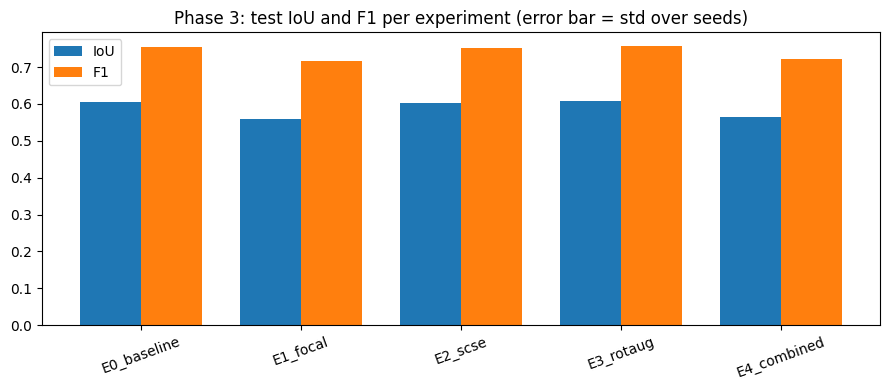

In [ ]:
def load_all_runs():
    rows = []
    for f in sorted(glob.glob(f'{OUT}/runs/*.json')):
        r = json.load(open(f))
        row = {'exp': r['name'], 'seed': r['seed']}
        row.update({f'test_{k}': v for k, v in r['test'].items()})
        row.update({f'val_{k}': v for k, v in r['val'].items()})
        rows.append(row)
    return pd.DataFrame(rows)

def summarise():
    runs = load_all_runs()
    g = runs.groupby('exp')
    tab = pd.DataFrame({
        'runs': g.size(),
        'IoU': g['test_IoU'].mean(), 'IoU std': g['test_IoU'].std(),
        'F1': g['test_F1'].mean(), 'Precision': g['test_Precision'].mean(), 'Recall': g['test_Recall'].mean(),
        'val_IoU': g['val_IoU'].mean(),
    }).reindex([e for e in EXPERIMENTS if e in g.groups])
    tab['IoU gain vs E0'] = tab['IoU'] - tab.loc['E0_baseline', 'IoU']
    return tab

tab = summarise()
display(tab.round(4))
tab.round(4).to_csv(f'{OUT}/phase3_results.csv')
best_exp = tab['val_IoU'].idxmax()
print("Best experiment by VALIDATION IoU:", best_exp)

xs = np.arange(len(tab)); w = 0.38
err = tab['IoU std'].fillna(0).values if tab['runs'].max() > 1 else None
plt.figure(figsize=(9, 4))
plt.bar(xs - w / 2, tab['IoU'].values, w, yerr=err, capsize=3, label='IoU')
plt.bar(xs + w / 2, tab['F1'].values, w, label='F1')
plt.xticks(xs, tab.index, rotation=20); plt.legend()
plt.title("Phase 3: test IoU and F1 per experiment (error bar = std over seeds)")
plt.tight_layout(); plt.savefig(f'{OUT}/phase3_results.png', dpi=150); plt.show()

In [ ]:
to_confirm = list(dict.fromkeys(['E0_baseline', best_exp, 'E4_combined']))
print("Confirming:", to_confirm)
for seed in (123, 777):
    for name in to_confirm:
        run_experiment(name, seed)

tab = summarise()
display(tab.round(4))
tab.round(4).to_csv(f'{OUT}/phase3_results.csv')
final_exp = tab[tab['runs'] >= 3]['val_IoU'].idxmax()
print("\nFINAL experiment (best mean validation IoU among 3-seed configs):", final_exp)

Confirming: ['E0_baseline', 'E2_scse', 'E4_combined']
skip E0_baseline seed 123 (done)

E2_scse | seed 123 | {'loss': 'bce_dice', 'attn': 'scse', 'aug': 'flip'}
[E2_scse/123] ep 01 train 1.0224 | val IoU 0.4152 F1 0.5868
[E2_scse/123] ep 02 train 0.5306 | val IoU 0.4955 F1 0.6626
[E2_scse/123] ep 03 train 0.4588 | val IoU 0.5229 F1 0.6867
[E2_scse/123] ep 04 train 0.4116 | val IoU 0.5371 F1 0.6988
[E2_scse/123] ep 05 train 0.4063 | val IoU 0.5544 F1 0.7134
[E2_scse/123] ep 06 train 0.3951 | val IoU 0.5634 F1 0.7207
[E2_scse/123] ep 07 train 0.3877 | val IoU 0.5668 F1 0.7235
[E2_scse/123] ep 08 train 0.3941 | val IoU 0.5716 F1 0.7274
[E2_scse/123] ep 09 train 0.3811 | val IoU 0.5730 F1 0.7285
[E2_scse/123] ep 10 train 0.3849 | val IoU 0.5569 F1 0.7154
[E2_scse/123] ep 11 train 0.3872 | val IoU 0.5647 F1 0.7218
[E2_scse/123] ep 12 train 0.3676 | val IoU 0.5844 F1 0.7377
[E2_scse/123] ep 13 train 0.3588 | val IoU 0.5772 F1 0.7319
[E2_scse/123] ep 14 train 0.3640 | val IoU 0.5791 F1 0.7335